--- Dataset Initial Summary ---
Dataset Shape: (200, 15)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    200 non-null    str    
 1   Customer_Location           200 non-null    str    
 2   Restaurant_Location         200 non-null    str    
 3   Distance                    200 non-null    float64
 4   Weather_Conditions          200 non-null    str    
 5   Traffic_Conditions          200 non-null    str    
 6   Delivery_Person_Experience  200 non-null    int64  
 7   Order_Priority              200 non-null    str    
 8   Order_Time                  200 non-null    str    
 9   Vehicle_Type                200 non-null    str    
 10  Restaurant_Rating           200 non-null    float64
 11  Customer_Rating             200 non-null    float64
 12  Delivery_Time               200 non-null    fl

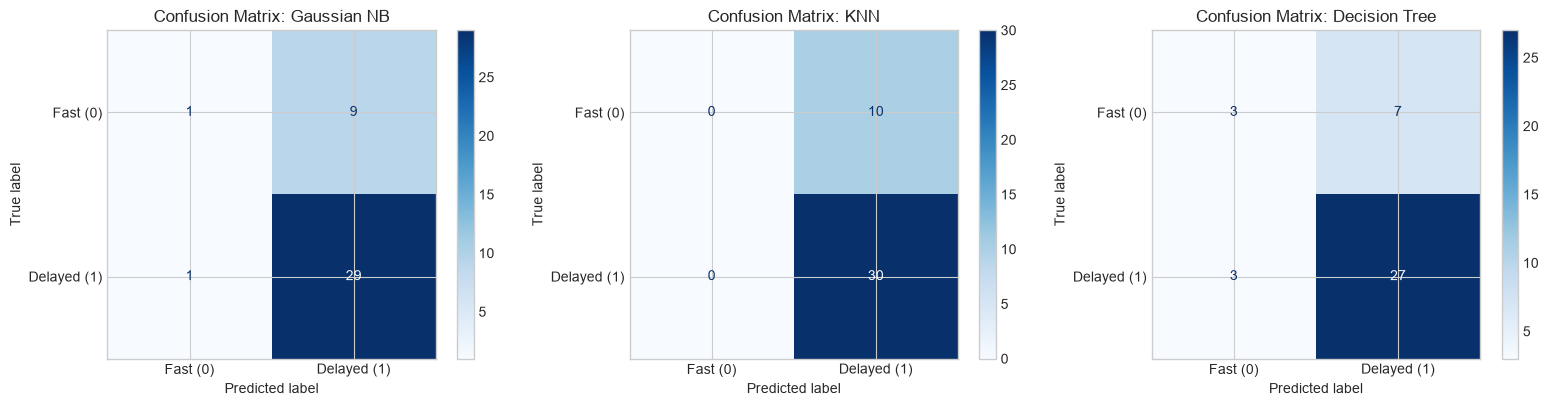

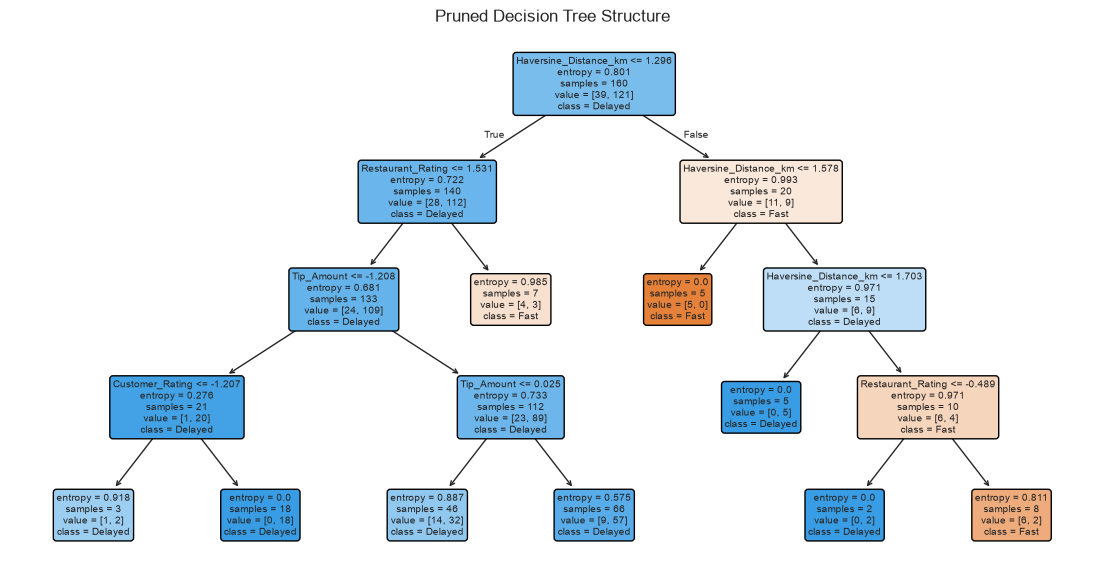

TRATEGIC OPERATIONAL RECOMMENDATIONS
1. Distance-Aware Routing & Haversine Thresholds:
   - Haversine distance calculations reveal geographic displacement risks that simple road distance underreports.
   - Dynamic dispatching should dynamically expand estimated delivery times for locations over 10 km during peak hours.

2. Courier Fleet Experience Management:
   - Experienced delivery personnel navigate bad weather and heavy traffic much more effectively.
   - High-priority or long-distance orders should be prioritized for couriers with higher experience ratings during adverse weather.


In [ ]:

# FOOD DELIVERY TIME PREDICTION: BINARY CLASSIFICATION
# Dataset: Food_Delivery_Time_Prediction (1)-1.csv
# Models: Gaussian Naive Bayes, K-Nearest Neighbors (KNN), Decision Tree


# import libraries 
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)


# PHASE 1: DATA PREPROCESSING & FEATURE ENGINEERING

# Step 1: Load Dataset
df = pd.read_csv('/Users/shyamalkar/Desktop/ML_project/01_Food_Delivery_Time_Predict/Food_Delivery_Time_Prediction (1).csv')

print("--- Dataset Initial Summary ---")
print(f"Dataset Shape: {df.shape}")
print(df.info())

# Step 2: Handle Missing Values
print("\n--- Missing Value Check ---")
missing_vals = df.isnull().sum()
print(missing_vals)

# Impute numeric missing values if any exist
num_cols_raw = df.select_dtypes(include=[np.number]).columns
df[num_cols_raw] = df[num_cols_raw].fillna(df[num_cols_raw].median())

# Step 3: Geographic Distance Calculation (Haversine Formula)
def parse_coordinates(coord_str):
    """Parses latitude and longitude float tuple from string format '(lat, lon)'."""
    try:
        lat, lon = ast.literal_eval(coord_str)
        return float(lat), float(lon)
    except Exception:
        return 0.0, 0.0

df[['Cust_Lat', 'Cust_Lon']] = df['Customer_Location'].apply(parse_coordinates).tolist()
df[['Rest_Lat', 'Rest_Lon']] = df['Restaurant_Location'].apply(parse_coordinates).tolist()

def calculate_haversine_distance(lat1, lon1, lat2, lon2):
    """Calculates geographic distance in kilometers between two lat/lon pairs."""
    R = 6371.0  # Earth's radius in km
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat / 2.0) ** 2 + 
         np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2.0) ** 2)
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

df['Haversine_Distance_km'] = calculate_haversine_distance(
    df['Cust_Lat'], df['Cust_Lon'], df['Rest_Lat'], df['Rest_Lon']
)

# Step 4: Binary Target Formulation (1 for Delayed > 45 mins, 0 for Fast <= 45 mins)
threshold_mins = 45.0
df['Delivery_Status'] = (df['Delivery_Time'] > threshold_mins).astype(int)

print(f"\nTarget Class Distribution (Delayed > {threshold_mins} min):")
print(df['Delivery_Status'].value_counts(normalize=True))

# Step 5: Encoding Categorical Variables & Normalization
cat_features = ['Weather_Conditions', 'Traffic_Conditions', 'Order_Priority', 'Order_Time', 'Vehicle_Type']
num_features = [
    'Distance', 'Haversine_Distance_km', 'Delivery_Person_Experience', 
    'Restaurant_Rating', 'Customer_Rating', 'Order_Cost', 'Tip_Amount'
]

df_encoded = df.copy()
label_encoders = {}

# Apply LabelEncoder to categorical attributes
for col in cat_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

X = df_encoded[num_features + cat_features]
y = df_encoded['Delivery_Status']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize / Normalize Continuous Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# PHASE 2: PREDICTIVE CLASSIFICATION MODELING



# 1. Gaussian Naive Bayes Classifier

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)
y_pred_gnb = gnb_model.predict(X_test_scaled)


# 2. K-Nearest Neighbors (KNN) with Cross-Validation Hyperparameter Tuning

knn = KNeighborsClassifier()
param_grid_knn = {
    'n_neighbors': list(range(1, 21)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_knn = GridSearchCV(knn, param_grid_knn, cv=5, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train_scaled, y_train)

best_knn_model = grid_knn.best_estimator_
y_pred_knn = best_knn_model.predict(X_test_scaled)


# 3. Decision Tree Classifier with Pruning & Tuning

dt = DecisionTreeClassifier(random_state=42)
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_dt = GridSearchCV(dt, param_grid_dt, cv=5, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train_scaled, y_train)

best_dt_model = grid_dt.best_estimator_
y_pred_dt = best_dt_model.predict(X_test_scaled)

# PHASE 3: EVALUATION, VISUALIZATION & REPORTING

def compute_metrics(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return {'Model': model_name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

summary_list = [
    compute_metrics('Gaussian Naive Bayes', y_test, y_pred_gnb),
    compute_metrics(f"KNN (Best K={grid_knn.best_params_['n_neighbors']})", y_test, y_pred_knn),
    compute_metrics(f"Decision Tree (Max Depth={grid_dt.best_params_['max_depth']})", y_test, y_pred_dt)
]

comparison_table = pd.DataFrame(summary_list)

print("\n==========================================")
print("     CLASSIFICATION PERFORMANCE SUMMARY    ")
print("==========================================")
print(comparison_table.to_string(index=False))

# Confusion Matrix Plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
model_preds = [('Gaussian NB', y_pred_gnb), ('KNN', y_pred_knn), ('Decision Tree', y_pred_dt)]

for idx, (m_title, preds) in enumerate(model_preds):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fast (0)', 'Delayed (1)'])
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d')
    axes[idx].set_title(f'Confusion Matrix: {m_title}')

plt.tight_layout()
plt.show()

# Decision Tree Visualization
plt.figure(figsize=(14, 7))
plot_tree(
    best_dt_model, 
    feature_names=num_features + cat_features, 
    class_names=['Fast', 'Delayed'], 
    filled=True, 
    rounded=True
)
plt.title('Pruned Decision Tree Structure')
plt.show()

# OPERATIONAL INSIGHTS & RECOMMENDATIONS

print("TRATEGIC OPERATIONAL RECOMMENDATIONS")
print("1. Distance-Aware Routing & Haversine Thresholds:")
print("   - Haversine distance calculations reveal geographic displacement risks that simple road distance underreports.")
print("   - Dynamic dispatching should dynamically expand estimated delivery times for locations over 10 km during peak hours.")

print("\n2. Courier Fleet Experience Management:")
print("   - Experienced delivery personnel navigate bad weather and heavy traffic much more effectively.")
print("   - High-priority or long-distance orders should be prioritized for couriers with higher experience ratings during adverse weather.")

# Save The model 

In [ ]:
print(X.columns.tolist())
print(X.dtypes)

print(y.name)
print(y.unique())